# Drought model: water availability → q_i → community ODE
Run all cells top to bottom. No data file needed.

In [1]:
# 0. Setup
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit
warnings.filterwarnings("ignore", message="Covariance of the parameters")

FORECAST_MONTHS = 24      # 24 months ≈ 730 days
SEED = 42                 # change for a different weather path
NOISE_SCALE = 1.0         # >1 = more erratic weather, <1 = calmer (use for scenarios)
MEAN_SHIFT = 0.0          # add a constant (e.g. -0.1) to make the climate drier on average

In [2]:
# 1. Water availability W(t) with no data file
# Monthly availability = seasonal mean + AR(1) anomaly + noise, all on the 0-1 scale.
# The constants below are the values your earlier notebook produced from the soil data
# (seasonal means Jan..Dec, AR(1) memory phi, noise sd, and the last observed state in Aug 2026).
SEAS_DEEP    = np.array([0.556, 0.639, 0.650, 0.599, 0.509, 0.374, 0.229, 0.130, 0.094, 0.111, 0.236, 0.401])
SEAS_SHALLOW = np.array([0.738, 0.738, 0.667, 0.589, 0.447, 0.257, 0.083, 0.045, 0.123, 0.326, 0.576, 0.686])
PHI_D, PHI_S = 0.853, 0.571
SD_D,  SD_S  = 0.088, 0.135
CORR = 0.59                                   # deep and shallow shocks are correlated
LAST_D, LAST_S = 0.071, 0.017                 # availability in Aug 2026 (t = 0)
ANOM_D, ANOM_S = -0.059, -0.028               # anomaly in Aug 2026

rng = np.random.default_rng(SEED)
months = (8 + np.arange(1, FORECAST_MONTHS + 1) - 1) % 12              # Sep, Oct, ... (0-indexed month)
a_d, a_s = ANOM_D, ANOM_S
sma_d, sma_s = [], []
for m in months:
    z1, z2 = rng.standard_normal(2)
    e_d = SD_D * NOISE_SCALE * z1
    e_s = SD_S * NOISE_SCALE * (CORR * z1 + np.sqrt(1 - CORR ** 2) * z2)
    a_d, a_s = PHI_D * a_d + e_d, PHI_S * a_s + e_s
    sma_d.append(np.clip(SEAS_DEEP[m] + MEAN_SHIFT + a_d, 0, 1))
    sma_s.append(np.clip(SEAS_SHALLOW[m] + MEAN_SHIFT + a_s, 0, 1))

# month starts counted in days from 1 Aug 2026 (t = 0 is the last observed month)
month_len = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
t_nodes = np.concatenate(([0.0], np.cumsum(month_len[(np.arange(8, 8 + FORECAST_MONTHS)) % 12])))
t_nodes_d = t_nodes_s = t_nodes
w_nodes_d = np.concatenate(([LAST_D], sma_d))
w_nodes_s = np.concatenate(([LAST_S], sma_s))

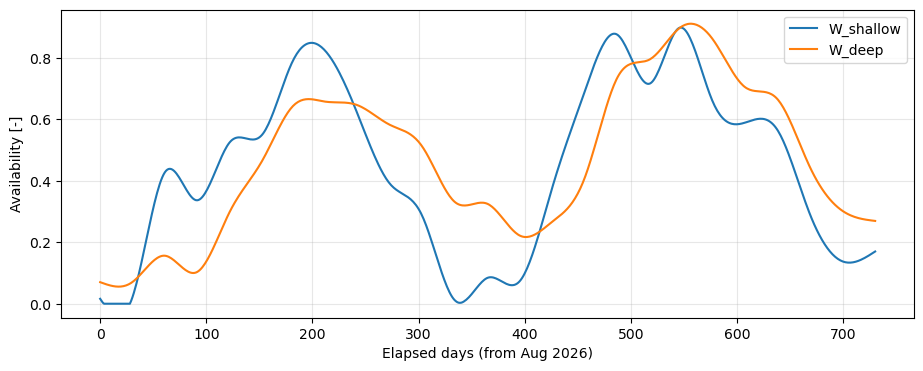

In [3]:
# 3. Continuous W functions (cubic splines) and SMA_i(t)
cs_deep, cs_shallow = CubicSpline(t_nodes_d, w_nodes_d, bc_type="natural"), CubicSpline(t_nodes_s, w_nodes_s, bc_type="natural")
T_END = float(t_nodes_d[-1])
W_deep_spline = lambda t: cs_deep(np.clip(np.asarray(t, float), t_nodes_d[0], t_nodes_d[-1]))
W_shallow_spline = lambda t: cs_shallow(np.clip(np.asarray(t, float), t_nodes_s[0], t_nodes_s[-1]))

def smooth_below_zero_floor(x, floor=1e-3, half_width=0.01):
    x = np.asarray(x, float)
    u = np.clip((x + half_width) / (2 * half_width), 0, 1)
    b = u * u * (3 - 2 * u)
    return (1 - b) * floor + b * x
W_deep_smooth_floor = lambda t: smooth_below_zero_floor(W_deep_spline(t))
# NB: the shallow spline can also overshoot below 0 / above 1, so floor it too and cap at 1
W_shallow_safe = lambda t: np.clip(smooth_below_zero_floor(W_shallow_spline(t)), 1e-3, 1.0)

def SMA(t, om):
    """Water availability for a species with rooting parameter om (1 = shallow roots, 0 = deep roots)."""
    return np.clip(om * W_shallow_safe(t) + (1 - om) * W_deep_smooth_floor(t), 1e-3, 1.0)

tg = np.linspace(0, T_END, 600)
plt.figure(figsize=(11, 4)); plt.plot(tg, W_shallow_safe(tg), label="W_shallow"); plt.plot(tg, W_deep_smooth_floor(tg), label="W_deep")
plt.xlabel("Elapsed days (from Aug 2026)"); plt.ylabel("Availability [-]"); plt.legend(); plt.grid(alpha=.3); plt.show()

In [4]:
# 4. Drought-sensitivity exponents q_i  (R = W**q), from qi_calculation notebook
def fit_q(W, R):
    W, R = np.asarray(W, float), np.asarray(R, float)
    x, y = np.log(W), np.log(R)
    q_log = np.sum(x * y) / np.sum(x ** 2)
    q_nls, _ = curve_fit(lambda w, q: w ** q, W, R, p0=[1.0])
    return q_log, q_nls[0]

q_table = {}
q_table["Thymus vulgaris"] = fit_q([0.75, 0.50], [0.938, 0.706])
q_table["Festuca arundinacea"] = fit_q([0.8, 0.65, 0.5, 0.35], np.array([0.14, 0.113, 0.073, 0.067]) / 0.163)

wue = np.array([0.249, 0.209, 0.240]); Wa = np.array([50, 75, 100.]) / 100
Ra = (wue * Wa) / (wue * Wa)[-1]
q_table["Amburana cearensis"] = fit_q(Wa[:2], Ra[:2])

Wd = np.array([1.0, 0.75, 0.5]); yld_mean = np.array([647.9, 614.4, 588.8])         # cocksfoot, mean of cultivars
q_table["Dactylis glomerata"] = fit_q(Wd[1:], yld_mean[1:] / yld_mean[0])

def _rt(x): return (52.4281 + 5.4403 * np.log(3000.03 - (x - 3000.01))) / 100
def _rw(x): return 10.7557 * np.exp(0.000492 * (3000.03 - (x - 3000.01))) / 100
psi = np.array([3000, 4000, 5000.]); q_table["Eragrostis lehmanniana"] = fit_q((6000 - psi) / (6000 - 1350), _rt(psi) * _rw(psi))

rain, dmat = np.array([687.5, 513.5]), np.array([1810., 570.])
q_table["Lupinus albus"] = fit_q([rain[1] / rain[0]], [dmat[1] / dmat[0]])

print(f"{'species':<24}{'q (log)':>9}{'q (NLS)':>9}")
for n, (a, b) in q_table.items(): print(f"{n:<24}{a:9.2f}{b:9.2f}")

species                   q (log)  q (NLS)
Thymus vulgaris              0.46     0.44
Festuca arundinacea          0.93     0.93
Amburana cearensis           1.03     1.09
Dactylis glomerata           0.14     0.15
Eragrostis lehmanniana       1.31     1.58
Lupinus albus                3.96     3.96


In [5]:
# 5. Species parameters
# q from NLS above.  omega: 1 = shallow roots, 0 = deep roots.
# omega, r0, Wc, d are PLACEHOLDERS (Amburana 0.7 and Lupinus 0.4 come from your plots) - calibrate / sweep them.
params = {   #  omega  r0     Wc    d
    "Thymus vulgaris":        (0.6, 0.020, 0.25, 0.015),
    "Festuca arundinacea":    (0.7, 0.020, 0.30, 0.020),
    "Amburana cearensis":     (0.7, 0.020, 0.30, 0.020),
    "Dactylis glomerata":     (0.7, 0.020, 0.30, 0.020),
    "Eragrostis lehmanniana": (0.5, 0.020, 0.25, 0.015),
    "Lupinus albus":          (0.4, 0.020, 0.35, 0.025),
}
names = list(params); N = len(names)
q = np.array([q_table[n][1] for n in names])
omega, r0, Wc, d = (np.array([params[n][k] for n in names]) for k in range(4))

K0, eta = 400.0, 0.0                                   # carrying capacity, habitat loss fraction
c = np.zeros(N); P = lambda t: 0.0                     # pollution sensitivity and P(t) (off)
alpha = np.full((N, N), 0.5); np.fill_diagonal(alpha, 0.0)   # competition matrix (placeholder)
B_min = 1e-2                                           # below this a species counts as extinct

In [6]:
# 6. Community ODE with drought-loss term
def drought_loss(w, d_i, Wc_i):
    return d_i * np.maximum(0.0, (Wc_i - w) / Wc_i) ** 2

def rhs(t, B, compete=True, active=None, d_use=None):
    B = np.maximum(B, 0.0)
    dd = d if d_use is None else d_use
    w = np.array([SMA(t, om) for om in omega]).ravel()
    comp = (alpha @ B) if compete else 0.0
    growth = r0 * w ** q * (1 - c * P(t)) * (1 - (B + comp) / ((1 - eta) * K0))
    dB = B * (growth - drought_loss(w, dd, Wc))
    return dB if active is None else dB * active

def simulate(B0, compete=True, active=None, d_use=None):
    sol = solve_ivp(rhs, [0, T_END], B0, t_eval=np.arange(0, T_END + 1), args=(compete, active, d_use),
                    method="LSODA", rtol=1e-8, atol=1e-10)
    return sol.t, np.maximum(sol.y, 0.0)

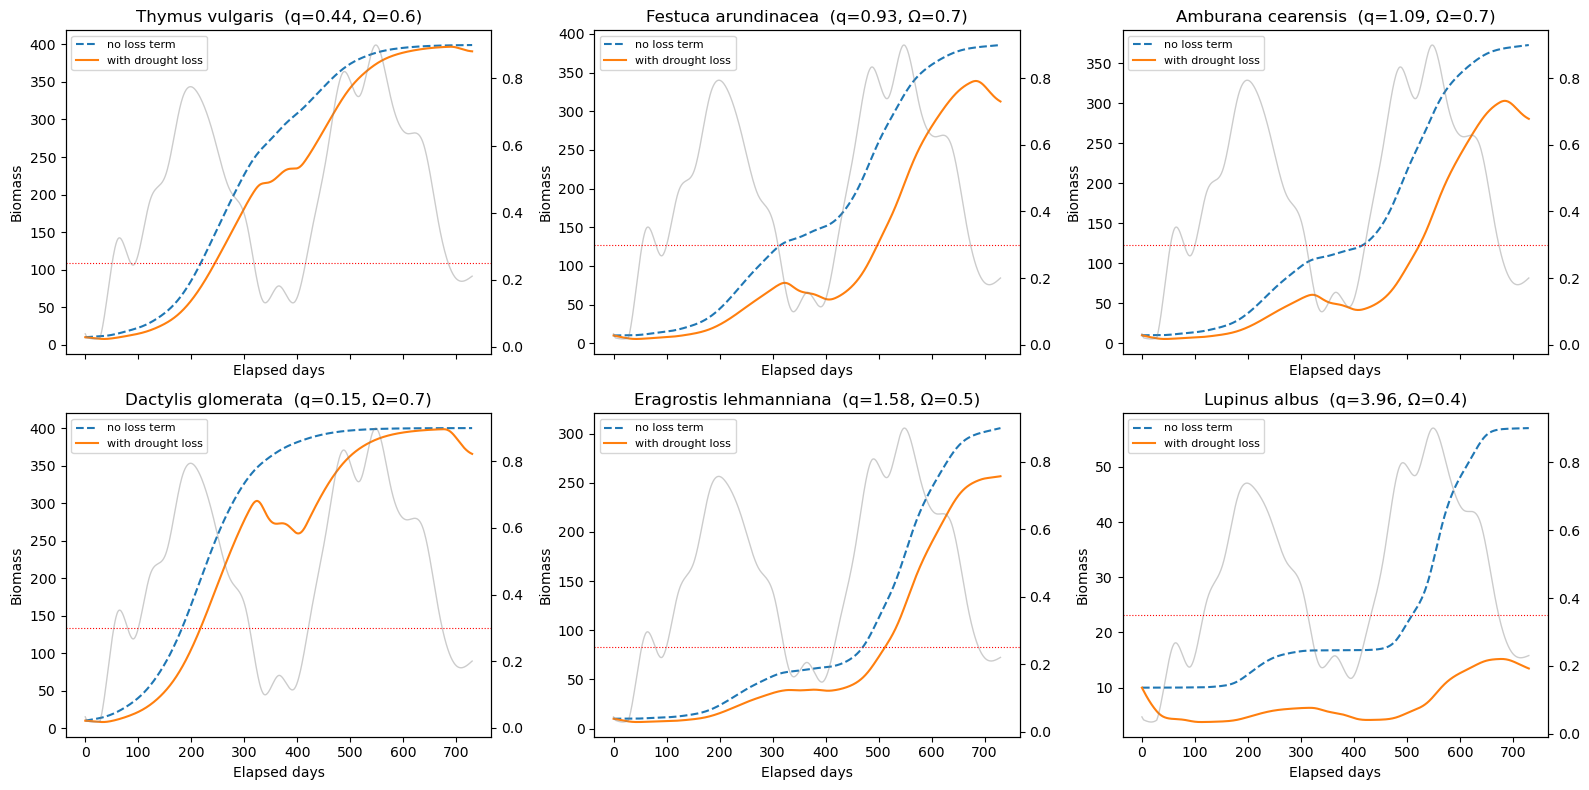

In [7]:
# 7. Validation: each species alone (no competition), with vs without the loss term
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
for i, ax in enumerate(axes.ravel()):
    act = np.zeros(N); act[i] = 1; y0 = np.zeros(N); y0[i] = 10.0
    for label, dd, ls in [("no loss term", np.zeros(N), "--"), ("with drought loss", d, "-")]:
        t, Y = simulate(y0, compete=False, active=act, d_use=dd); ax.plot(t, Y[i], ls, label=label)
    ax.set_title(f"{names[i]}  (q={q[i]:.2f}, Ω={omega[i]})"); ax.set_xlabel("Elapsed days"); ax.set_ylabel("Biomass"); ax.legend(fontsize=8)
    ax2 = ax.twinx(); ax2.plot(t, SMA(t, omega[i]), color="gray", alpha=.4, lw=1); ax2.axhline(Wc[i], color="r", ls=":", lw=.8)
plt.tight_layout(); plt.show()

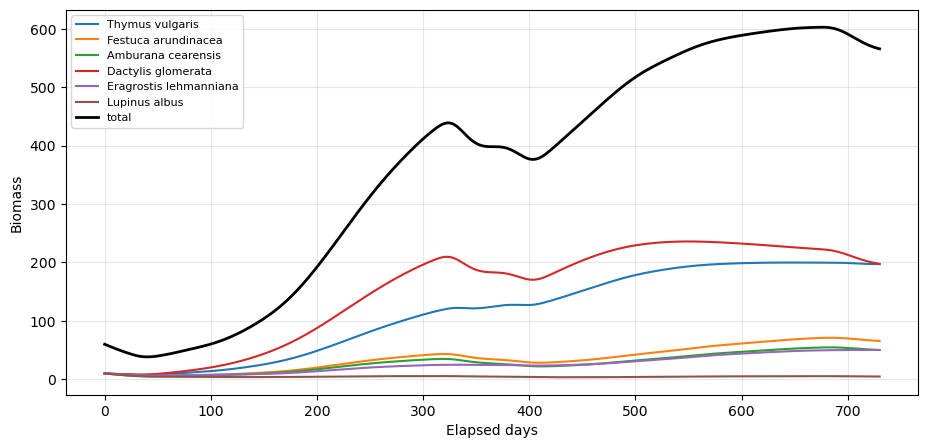

final biomass: {'Thymus vulgaris': np.float64(197.3), 'Festuca arundinacea': np.float64(65.7), 'Amburana cearensis': np.float64(50.2), 'Dactylis glomerata': np.float64(197.6), 'Eragrostis lehmanniana': np.float64(50.2), 'Lupinus albus': np.float64(4.7)}
extinct (B < B_min): none


In [8]:
# 8. Full community (competition on)
t, Y = simulate(np.full(N, 10.0), compete=True)
plt.figure(figsize=(11, 5))
for i, n in enumerate(names): plt.plot(t, Y[i], label=n)
plt.plot(t, Y.sum(0), "k", lw=2, label="total"); plt.xlabel("Elapsed days"); plt.ylabel("Biomass"); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()
print("final biomass:", dict(zip(names, Y[:, -1].round(1))))
print("extinct (B < B_min):", [n for n, b in zip(names, Y[:, -1]) if b < B_min] or "none")